# HW Assignment #2

## 1. Load music metadata with audio-features of the various tracks from different genres

In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, rand_score

df = pd.read_csv("fma_dataset_filtered.csv")
print("Shape:", df.shape)
display(df.head(3))
display(df["genre"].value_counts())

Shape: (2406, 524)


,track_id,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,...,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy,genre
0,2,7.180653,5.230309,0.249321,1.347620,1.482478,0.531371,1.481593,2.691455,0.866868,...,0.085629,0.071289,0.0,2.089872,0.061448,168,165.922,0.675894,0.634476,Hip-Hop
1,3,1.888963,0.760539,0.345297,2.295201,1.654031,0.067592,1.366848,1.054094,0.108103,...,0.084578,0.063965,0.0,1.716724,0.069330,237,126.957,0.528643,0.817461,Hip-Hop
2,5,0.527563,-0.077654,-0.279610,0.685883,1.937570,0.880839,-0.923192,-0.927232,0.666617,...,0.053114,0.041504,0.0,2.193303,0.044861,206,100.260,0.745566,0.701470,Hip-Hop


genre
Hip-Hop                910
Folk                   874
Old-Time / Historic    357
Classical              265
Name: count, dtype: int64

## 2. Do the necessary preprocessing of the dataset

In [81]:
y_genre = df["genre"].copy()

X = df.drop(columns=["track_id", "genre"]).copy()
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

unique_features = X.columns[X.nunique(dropna=True) <= 1].tolist()
X = X.drop(columns=unique_features)
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 3. Visualize the dataset with PCA and t-SNE

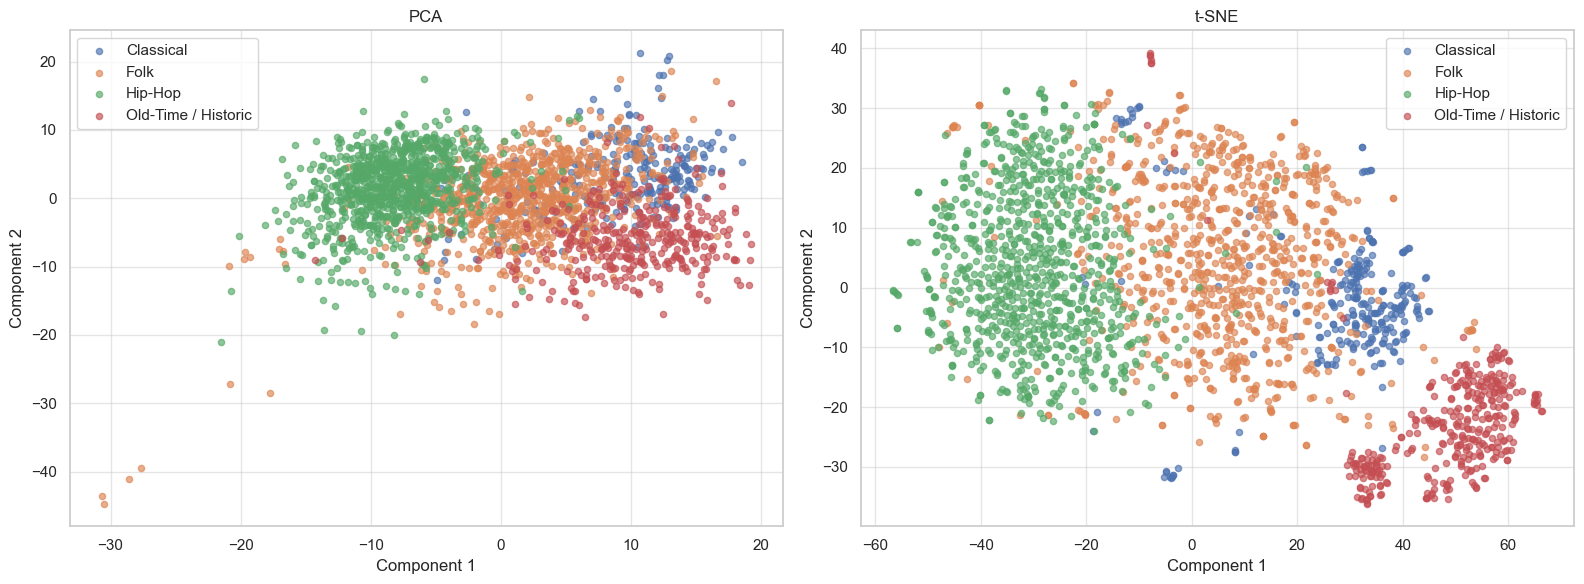

In [82]:
pca_2 = PCA(n_components=2, random_state=42)
X_pca = pca_2.fit_transform(X_scaled)

tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
genres = np.unique(y_genre)
for ax, coords, title in zip(axes, [X_pca, X_tsne], ["PCA", "t-SNE"]):
    for genre in genres:
        mask = (np.asarray(y_genre) == genre)
        ax.scatter(coords[mask, 0], coords[mask, 1], s=20, alpha=0.65, label=genre)
    ax.set_title(title)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.legend()
plt.tight_layout()
plt.show()

## 4. Plot PCA explained variance dependence from the number of principal components

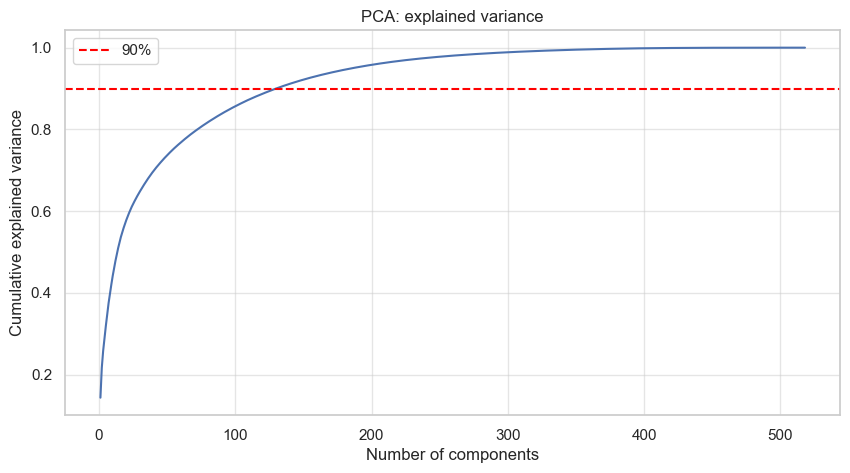

2 components save 21.64% of variance


In [83]:
pca_full = PCA().fit(X_scaled)
explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(0.90, linestyle="--", color="red", label="90%")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: explained variance")
plt.legend()
plt.show()

variance_2 = 100 * cumulative_variance[1]
print(f"2 components save {variance_2:.2f}% of variance")

## 5. Apply K-Means clustering to the data without a column “genre”. Find optimal number of clusters (i) based on Silhouette metric and (ii) based on Rand Index metric (using knowledge about genres) from the range of possible #clusters from 2 to 6

In [84]:
results = []
models = {}
for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    models[k] = model
    results.append({
        "k": k,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Rand Index": rand_score(y_genre, labels)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

best_k_silhouette = int(results_df.loc[results_df["Silhouette"].idxmax(), "k"])
best_k_rand = int(results_df.loc[results_df["Rand Index"].idxmax(), "k"])
print("Optimal k by Silhouette:", best_k_silhouette)
print("Optimal k by Rand Index:", best_k_rand)

,k,Silhouette,Rand Index
0,2,0.1096,0.6803
1,3,0.0899,0.7856
2,4,0.0756,0.7740
3,5,0.0718,0.8047
4,6,0.0721,0.8048


Optimal k by Silhouette: 2
Optimal k by Rand Index: 6


## 6. Questions
### 6.1. Whether visualization results from p.3 reflects the real distribution of the genres? Which algorithm performs better and why?
t-SNE shows better visual separation than PCA, but the genres still overlap. Therefore, neither method perfectly reflects the actual genre distribution. t-SNE performs better for visualising local groups because it preserves local similarities, while PCA maximizes explained variance.

### 6.2. What percentage of the explained variance was left after we have excluded all but 2 components in p.4?
21.64% remains, while 78.36% is lost

### 6.3. Can Silhouette metric be chosen as optimal criteria for the number of clusters for that data? Is Rand index is more appropriate?
Silhouette can be used to evaluate clustering without knowing the genres, but its values are quite low for this dataset, which indicates poor cluster separation. Rand Index is more appropriate if we want to compare the clusters with actual genres. Silhouette selects 2 clusters, while Rand Index selects 6 clusters.

### 6.4. If you don’t know the genre but need to build a song recommendation system based on the similarity between the songs in this dataset - what would you do?
I would use the Nearest Neighbors algorithm to find songs with similar audio features and recommend the nearest ones.

### 6.5* How do you think, what is the most important feature (from the initial dataset) for the cluster division?
tempo, danceability and	energy may help split genres, especially here because hip-hop, folk, classic and Old-Time/Historic are very different